 Tabular Q-learning and SARSA for Frozen Lake
#
In this notebook, we will use Q-learning and SARSA methods to solve Frozen Lake.

Environment: (https://gymnasium.farama.org/environments/toy_text/frozen_lake/).

## Execução local
Requer Python 3.10+ e um kernel apontando para um ambiente virtual. Dependências na primeira célula de código.

In [ ]:
# Instalação no kernel ativo (%pip, não !pip). Execute uma vez e reinicie o kernel se necessário.
# [toy-text] inclui o pygame, usado no render do FrozenLake.
# imageio_ffmpeg empacota o binário do ffmpeg: não é preciso instalar ffmpeg no sistema.
%pip install -q "gymnasium[toy-text]>=1.0,<2.0" numpy matplotlib seaborn imageio imageio_ffmpeg

In [30]:
import random
import sys

import gymnasium as gym
import imageio
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

# Reprodutibilidade
SEED = 42
random.seed(SEED)
np.random.seed(SEED)               # legado
rng = np.random.default_rng(SEED)  # preferir este gerador nas próximas células

# Registro de versões
print(f"python {sys.version.split()[0]} | gymnasium {gym.__version__} | numpy {np.__version__}")

python 3.12.12 | gymnasium 1.4.0 | numpy 2.5.4


In [31]:
from gymnasium.envs.toy_text.frozen_lake import generate_random_map

# Configuração do ambiente (parametrizada para facilitar experimentos)
MAP_SIZE = 8
P_FROZEN = 0.9
IS_SLIPPERY = False   # True para transições estocásticas

desc = generate_random_map(size=MAP_SIZE, p=P_FROZEN, seed=SEED)  # SEED definido na Parte 1

env = gym.make(
    "FrozenLake-v1",
    desc=desc,
    is_slippery=IS_SLIPPERY,
    render_mode="rgb_array",
)
env.action_space.seed(SEED)

print("\n".join(desc))
print(env.observation_space, env.action_space, f"max_steps={env.spec.max_episode_steps}")
env.spec

SFFFFHFF
FFFHFFFF
FFFFFFHF
FFFFFFFH
FFFFFFFF
FFFFFFFF
FFFFFFFF
FFFFFFFG
Discrete(64) Discrete(4) max_steps=100


EnvSpec(id='FrozenLake-v1', entry_point='gymnasium.envs.toy_text.frozen_lake:FrozenLakeEnv', reward_threshold=0.7, nondeterministic=False, max_episode_steps=100, order_enforce=True, disable_env_checker=False, kwargs={'map_name': '4x4', 'desc': ['SFFFFHFF', 'FFFHFFFF', 'FFFFFFHF', 'FFFFFFFH', 'FFFFFFFF', 'FFFFFFFF', 'FFFFFFFF', 'FFFFFFFG'], 'is_slippery': False, 'render_mode': 'rgb_array'}, namespace=None, name='FrozenLake', version=1, additional_wrappers=(), vector_entry_point=None)

Actions: {0: 'move left', 1: 'move down', 2: 'move right', 3: 'move up'}
Estado inicial: 0 | estados: 64 | ações: 4


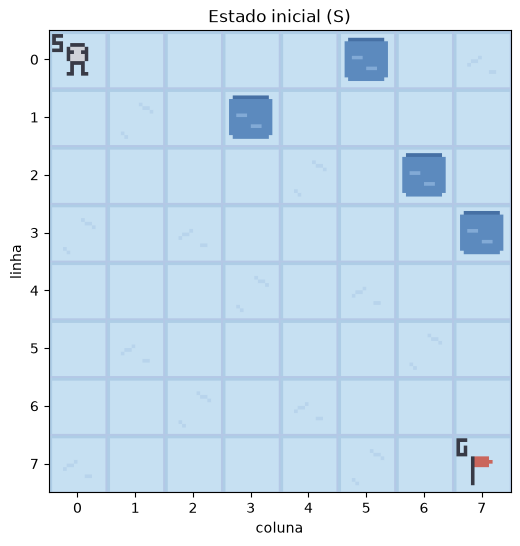

In [32]:
# Convenção de ações do FrozenLake (Gymnasium)
LEFT, DOWN, RIGHT, UP = 0, 1, 2, 3
ACTION_NAMES = ["move left", "move down", "move right", "move up"]

# Dimensões derivadas do ambiente, não inferidas
N_ROWS, N_COLS = env.unwrapped.nrow, env.unwrapped.ncol
N_STATES, N_ACTIONS = env.observation_space.n, env.action_space.n
assert len(ACTION_NAMES) == N_ACTIONS, "Lista de ações incompatível com o ambiente"
print("Actions:", dict(enumerate(ACTION_NAMES)))


def plot_image(img, n_rows, n_cols, title=None):
    """Exibe o frame renderizado com eixos centrados nas células."""
    fig, ax = plt.subplots(figsize=(6, 6))
    ax.imshow(img, extent=[0, n_cols, n_rows, 0])
    ax.set_xticks(np.arange(n_cols) + 0.5, labels=range(n_cols))
    ax.set_yticks(np.arange(n_rows) + 0.5, labels=range(n_rows))
    ax.set_xlabel("coluna")
    ax.set_ylabel("linha")
    if title:
        ax.set_title(title)
    plt.show()


# Primeira chamada de reset: aplica a semente do ambiente (uma única vez)
obs, info = env.reset(seed=SEED)
print(f"Estado inicial: {obs} | estados: {N_STATES} | ações: {N_ACTIONS}")
plot_image(env.render(), N_ROWS, N_COLS, "Estado inicial (S)")

In [33]:
# step() devolve: (próximo estado, recompensa, terminated, truncated, info)
#   terminated: estado terminal verdadeiro (buraco 'H' ou objetivo 'G')
#   truncated : corte por limite de passos (não é terminal real)
#   sucesso   : reward == 1.0 (somente ao atingir 'G')

env.reset()  # sem seed: a semente já foi aplicada na primeira chamada (Parte 3)

print("passo | ação | (linha, col) | casa | recompensa | terminated | truncated | info")
for i in range(20):
    action = env.action_space.sample()
    state, reward, terminated, truncated, info = env.step(action)

    row, col = divmod(state, N_COLS)
    tile = desc[row][col]
    print(f"{i+1:>3} | {ACTION_NAMES[action]:<10} | ({row},{col}) | {tile} | "
          f"{reward} | {terminated} | {truncated} | {info}")

    if terminated or truncated:
        break

passo | ação | (linha, col) | casa | recompensa | terminated | truncated | info
  1 | move left  | (0,0) | S | 0 | False | False | {'prob': 1.0}
  2 | move up    | (0,0) | S | 0 | False | False | {'prob': 1.0}
  3 | move right | (0,1) | F | 0 | False | False | {'prob': 1.0}
  4 | move down  | (1,1) | F | 0 | False | False | {'prob': 1.0}
  5 | move down  | (2,1) | F | 0 | False | False | {'prob': 1.0}
  6 | move up    | (1,1) | F | 0 | False | False | {'prob': 1.0}
  7 | move left  | (1,0) | F | 0 | False | False | {'prob': 1.0}
  8 | move right | (1,1) | F | 0 | False | False | {'prob': 1.0}
  9 | move left  | (1,0) | F | 0 | False | False | {'prob': 1.0}
 10 | move left  | (1,0) | F | 0 | False | False | {'prob': 1.0}
 11 | move right | (1,1) | F | 0 | False | False | {'prob': 1.0}
 12 | move up    | (0,1) | F | 0 | False | False | {'prob': 1.0}
 13 | move right | (0,2) | F | 0 | False | False | {'prob': 1.0}
 14 | move up    | (0,2) | F | 0 | False | False | {'prob': 1.0}
 15 | move

In [34]:
def random_policy_baseline(env, n_episodes=1000):
    """Taxa de sucesso e comprimento médio de episódio de uma política uniforme."""
    successes, lengths = 0, []
    for _ in range(n_episodes):
        env.reset()
        done, steps, reward = False, 0, 0.0
        while not done:
            _, reward, terminated, truncated, _ = env.step(env.action_space.sample())
            done = terminated or truncated
            steps += 1
        successes += reward  # reward do último passo: 1.0 só se chegou em G
        lengths.append(steps)
    return successes / n_episodes, float(np.mean(lengths))

success_rate, mean_len = random_policy_baseline(env)
print(f"Baseline aleatória: sucesso = {success_rate:.1%} | passos médios = {mean_len:.1f}")
env.reset();  # deixa o ambiente pronto para a próxima etapa

Baseline aleatória: sucesso = 5.3% | passos médios = 41.8


In [35]:
from pathlib import Path

from gymnasium.wrappers import RecordVideo
from IPython.display import Video, display

VIDEO_DIR = Path("videos")


def make_env(record_prefix=None):
    """Cria o ambiente com o MESMO mapa (desc). Com record_prefix, grava só o 1º episódio."""
    e = gym.make("FrozenLake-v1", desc=desc, is_slippery=IS_SLIPPERY, render_mode="rgb_array")
    e.action_space.seed(SEED)
    if record_prefix is not None:
        e = RecordVideo(
            e,
            video_folder=str(VIDEO_DIR),
            name_prefix=record_prefix,
            episode_trigger=lambda ep: ep == 0,  # apenas o episódio 0
        )
    return e


def record_random_episode(prefix="before_training", max_steps=100):
    rec_env = make_env(record_prefix=prefix)
    state, info = rec_env.reset(seed=SEED)
    for i in range(max_steps):
        action = rec_env.action_space.sample()
        state, reward, terminated, truncated, info = rec_env.step(action)
        if terminated or truncated:
            outcome = "objetivo" if reward == 1.0 else ("buraco" if terminated else "truncado")
            print(f"Episódio encerrado no passo {i+1}: {outcome} | "
                  f"última ação: {ACTION_NAMES[action]} | estado final: {state}")
            break
    rec_env.close()  # garante que o arquivo seja finalizado


record_random_episode()

video_path = sorted(VIDEO_DIR.glob("before_training*.mp4"))[-1]
display(Video(str(video_path), embed=True, width=400))

/home/glauber/Projetos/others/notebooks/.venv/lib/python3.12/site-packages/gymnasium/wrappers/rendering.py:298: UserWarning: WARN: Overwriting existing videos at /home/glauber/Projetos/others/notebooks/videos folder (try specifying a different `video_folder` for the `RecordVideo` wrapper if this is not desired)
  logger.warn(


Episódio encerrado no passo 20: buraco | última ação: move down | estado final: 11


In [36]:
from IPython.display import Video, display

display(Video(str(video_path), embed=True, width=400))

In [37]:
from base64 import b64encode
from pathlib import Path

from IPython.display import HTML, display


def render_mp4(video_path, width=400) -> HTML:
    """Embute um MP4 local no notebook via data URI (base64) e devolve o HTML pronto."""
    data = b64encode(Path(video_path).read_bytes()).decode("ascii")
    return HTML(
        f'<video width="{width}" controls>'
        f'<source src="data:video/mp4;base64,{data}" type="video/mp4">'
        f"</video>"
    )


# Caminho derivado do disco, não de uma variável implícita
before_training = sorted(VIDEO_DIR.glob("before_training*.mp4"))[-1]
display(render_mp4(before_training))

##Building a Q-learning agent (off-policy) or a SARSA agent (on-policy)

![QL](https://github.com/dudeperf3ct/RL_Notebooks/blob/master/TD/images/ql.png?raw=1)
![QL](https://github.com/dudeperf3ct/RL_Notebooks/blob/master/TD/images/sarsa.png?raw=1)

In [38]:
class FrozenLakeAgent:

    def __init__(
        self,
        alpha_learning_rate: float,
        initial_epsilon: float,
        epsilon_decay: float,
        final_epsilon: float,
        gamma_discount_factor: float,
        state_size: int,
        action_size: int,
        is_using_Sarsa: bool,
        seed: int = 0,
        verbose: bool = True,
    ):
        """Agente tabular com política ε-greedy (Q-learning ou SARSA).

        Args:
            alpha_learning_rate: taxa de aprendizado α, em (0, 1].
            initial_epsilon: ε inicial.
            epsilon_decay: decremento LINEAR de ε por chamada de decay_epsilon().
            final_epsilon: piso de ε.
            gamma_discount_factor: fator de desconto γ, em [0, 1].
            state_size: número de estados discretos.
            action_size: número de ações discretas.
            is_using_Sarsa: True = SARSA (on-policy); False = Q-learning (off-policy).
            seed: semente do gerador do agente (única fonte de aleatoriedade).
            verbose: imprime o método selecionado.
        """
        assert 0.0 < alpha_learning_rate <= 1.0, "α deve estar em (0, 1]"
        assert 0.0 <= gamma_discount_factor <= 1.0, "γ deve estar em [0, 1]"
        assert 0.0 <= final_epsilon <= initial_epsilon <= 1.0, "ε inconsistente"

        self.alpha_learning_rate = alpha_learning_rate
        self.gamma_discount_factor = gamma_discount_factor
        self.epsilon = initial_epsilon
        self.epsilon_decay = epsilon_decay
        self.final_epsilon = final_epsilon
        self.state_size = state_size
        self.action_size = action_size
        self.is_using_Sarsa = is_using_Sarsa

        self.training_error = []  # δ (com sinal) por atualização
        self.q_table = np.zeros((state_size, action_size))
        self.rng = np.random.default_rng(seed)

        if verbose:
            print("Using Sarsa method" if is_using_Sarsa else "Using Q-learning method")

    def get_Q_Table(self):
        return self.q_table

    def eval_state(self, state):
        """Ação gulosa, com desempate aleatório entre ações de mesmo Q."""
        q = self.q_table[state]
        best = np.flatnonzero(q == q.max())
        return int(self.rng.choice(best))

    greedy_action = eval_state  # alias com nome mais explícito

    def choose_action(self, state):
        """ε-greedy: explora com prob. ε, senão age de forma gulosa."""
        if self.rng.random() < self.epsilon:
            return int(self.rng.integers(self.action_size))  # sem depender do env
        return self.eval_state(state)

    def update(self, state, action, reward, terminated, next_state, next_action=None):
        """Atualização TD. Passe `terminated`, NUNCA `terminated or truncated`.
        No SARSA, next_action deve ser a ação que será EXECUTADA em next_state."""
        if terminated:
            target = reward
        elif self.is_using_Sarsa:
            assert next_action is not None, "SARSA exige next_action"
            target = reward + self.gamma_discount_factor * self.q_table[next_state, next_action]
        else:
            target = reward + self.gamma_discount_factor * np.max(self.q_table[next_state])

        td_error = target - self.q_table[state, action]
        self.q_table[state, action] += self.alpha_learning_rate * td_error
        self.training_error.append(td_error)

    def decay_epsilon(self):
        self.epsilon = max(self.final_epsilon, self.epsilon - self.epsilon_decay)

## Hyperparameters

In [39]:
# Configuração do experimento (um único lugar, sem @param do Colab)
CONFIG = dict(
    alpha_learning_rate=0.5,
    nb_max_episodes=5000,
    start_epsilon=0.5,
    final_epsilon=0.1,
    gamma_discount_factor=0.95,
    test_freq=100,
)

# Compatibilidade com o restante do notebook (nomes originais)
alpha_learning_rate   = CONFIG["alpha_learning_rate"]
nb_max_episodes       = CONFIG["nb_max_episodes"]
start_epsilon         = CONFIG["start_epsilon"]
final_epsilon         = CONFIG["final_epsilon"]
gamma_discount_factor = CONFIG["gamma_discount_factor"]
test_freq             = CONFIG["test_freq"]

# Decaimento LINEAR por EPISÓDIO: chame agent.decay_epsilon() uma vez ao fim de cada episódio.
epsilon_decay = (start_epsilon - final_epsilon) / nb_max_episodes

is_using_Sarsa = False  # True = SARSA; False = Q-learning


def make_agent(use_sarsa: bool, seed: int = SEED) -> "FrozenLakeAgent":
    return FrozenLakeAgent(
        alpha_learning_rate=alpha_learning_rate,
        initial_epsilon=start_epsilon,
        epsilon_decay=epsilon_decay,
        final_epsilon=final_epsilon,
        gamma_discount_factor=gamma_discount_factor,
        state_size=N_STATES,
        action_size=N_ACTIONS,
        is_using_Sarsa=use_sarsa,
        seed=seed,
    )


agent = make_agent(is_using_Sarsa)

# Sanidade do cronograma de ε e do valor esperado de Q
eps_mean = (start_epsilon + final_epsilon) / 2
print(f"ε: {start_epsilon} → {final_epsilon} | decay/episódio = {epsilon_decay:.2e} | ε médio ≈ {eps_mean:.2f}")

Using Q-learning method
ε: 0.5 → 0.1 | decay/episódio = 8.00e-05 | ε médio ≈ 0.30


### Test accurracy

In [40]:
def evaluate_policy(agent, eval_env, n_episodes=100, max_steps=100, rng=None):
    """Avalia a política gulosa (ε = 0). Retorna (taxa_de_sucesso, passos_médios).
    Usa gerador próprio para o desempate: não perturba o RNG do agente nem o treino."""
    rng = rng if rng is not None else np.random.default_rng(SEED + 1)
    successes, lengths = 0, []
    for _ in range(n_episodes):
        state, _ = eval_env.reset()
        for steps in range(1, max_steps + 1):
            q = agent.q_table[state]
            action = int(rng.choice(np.flatnonzero(q == q.max())))
            state, reward, terminated, truncated, _ = eval_env.step(action)
            if terminated or truncated:
                successes += int(terminated and reward == 1.0)
                break
        lengths.append(steps)
    return successes / n_episodes, float(np.mean(lengths))


# Ambiente de avaliação separado, sem gravação de vídeo
eval_env = make_env()


# Compatibilidade com o nome original, que o loop de treino deve chamar
def test_accurracy(num_steps, num_episodes=100):
    return evaluate_policy(agent, eval_env, num_episodes, num_steps)[0]

In [41]:
def record_episode(policy, prefix, max_steps=100, fps=4):
    """Grava um episódio em MP4. `policy(state) -> action`.
    Usa um ambiente próprio: não depende do `env` global nem de wrappers."""
    rec_env = make_env()  # sem RecordVideo; mesmo mapa e configuração
    VIDEO_DIR.mkdir(exist_ok=True)
    path = VIDEO_DIR / f"{prefix}.mp4"

    state, _ = rec_env.reset(seed=SEED)
    frames, outcome = [rec_env.render()], "truncado"
    try:
        for _ in range(max_steps):
            state, reward, terminated, truncated, _ = rec_env.step(policy(state))
            frames.append(rec_env.render())
            if terminated or truncated:
                outcome = ("objetivo" if reward == 1.0
                           else "buraco" if terminated else "truncado")
                break
    finally:
        rec_env.close()

    imageio.mimwrite(path, frames, fps=fps)
    print(f"{prefix}: {len(frames) - 1} passos | desfecho: {outcome} | {path}")
    return path


# Política gulosa com RNG próprio (não perturba o agente)
_rng_video = np.random.default_rng(SEED + 2)
def greedy_policy(state):
    q = agent.q_table[state]
    return int(_rng_video.choice(np.flatnonzero(q == q.max())))

# Política aleatória, para o vídeo "antes" (mesma função, mesma pasta)
_rng_rand = np.random.default_rng(SEED + 3)
def random_policy(state):
    return int(_rng_rand.integers(N_ACTIONS))

# Uso, após o treino
after_training = record_episode(greedy_policy, "after_training")
display(Video(str(after_training), embed=True, width=400))

after_training: 40 passos | desfecho: buraco | videos/after_training.mp4


## Playing and Training

In [42]:
from tqdm import tqdm


def train(use_sarsa, seed=SEED, n_episodes=None, eval_every=None, n_eval=50, verbose=True):
    """Treina um agente do zero. Retorna (agent, hist). Sem dependência de globais mutáveis."""
    n_episodes = n_episodes or nb_max_episodes
    eval_every = eval_every or test_freq

    train_env, eval_env = make_env(), make_env()   # sem RecordVideo
    agent = make_agent(use_sarsa, seed)
    eval_rng = np.random.default_rng(seed + 1)     # desempate da avaliação isolado do treino
    max_steps = train_env.spec.max_episode_steps

    hist = dict(reward=[], steps=[], eval_episode=[], eval_success=[], eval_len=[])

    for ep in tqdm(range(n_episodes), disable=not verbose):
        state, _ = train_env.reset(seed=seed if ep == 0 else None)  # semente só no 1º reset
        action = agent.choose_action(state) if use_sarsa else None
        ep_reward, ep_steps, done = 0.0, 0, False

        while not done:
            if not use_sarsa:
                action = agent.choose_action(state)
            next_state, reward, terminated, truncated, _ = train_env.step(action)
            done = terminated or truncated

            # SARSA: só sorteia a próxima ação se o episódio não terminou de fato
            next_action = (agent.choose_action(next_state)
                           if use_sarsa and not terminated else None)
            agent.update(state, action, reward, terminated, next_state, next_action)

            state, action = next_state, next_action
            ep_reward += reward
            ep_steps += 1

        agent.decay_epsilon()                       # uma vez por episódio
        hist["reward"].append(ep_reward)
        hist["steps"].append(ep_steps)

        if (ep + 1) % eval_every == 0:
            success, mean_len = evaluate_policy(agent, eval_env, n_eval, max_steps, eval_rng)
            hist["eval_episode"].append(ep + 1)
            hist["eval_success"].append(success)
            hist["eval_len"].append(mean_len)
            if verbose:
                tqdm.write(f"ep {ep+1:>5} | treino(ε-greedy): {np.mean(hist['reward'][-eval_every:]):.2f} "
                           f"| teste(guloso): {success:.2f} | passos: {mean_len:.1f} | ε: {agent.epsilon:.3f}")

    train_env.close(); eval_env.close()
    return agent, hist


def make_greedy_policy(agent, seed):
    rng = np.random.default_rng(seed)
    def policy(state):
        q = agent.q_table[state]
        return int(rng.choice(np.flatnonzero(q == q.max())))
    return policy


# Uso
agent, hist = train(is_using_Sarsa)
print(f"max Q(S) = {agent.q_table[0].max():.3f}")   # referência: γ^(passos_mínimos − 1)
after_training = record_episode(make_greedy_policy(agent, SEED + 2), "after_training")
display(Video(str(after_training), embed=True, width=400))

Using Q-learning method


  1%|          | 55/5000 [00:00<00:09, 548.09it/s]

ep   100 | treino(ε-greedy): 0.19 | teste(guloso): 1.00 | passos: 16.0 | ε: 0.492


  4%|▍         | 200/5000 [00:00<00:07, 651.22it/s]

ep   200 | treino(ε-greedy): 0.91 | teste(guloso): 1.00 | passos: 14.0 | ε: 0.484


...

ep  4400 | treino(ε-greedy): 0.97 | teste(guloso): 1.00 | passos: 14.0 | ε: 0.148
ep  4500 | treino(ε-greedy): 0.95 | teste(guloso): 1.00 | passos: 14.0 | ε: 0.140
ep  4600 | treino(ε-greedy): 0.98 | teste(guloso): 1.00 | passos: 14.0 | ε: 0.132


 96%|█████████▋| 4815/5000 [00:05<00:00, 1028.75it/s]

ep  4700 | treino(ε-greedy): 0.98 | teste(guloso): 1.00 | passos: 14.0 | ε: 0.124
ep  4800 | treino(ε-greedy): 0.95 | teste(guloso): 1.00 | passos: 14.0 | ε: 0.116
ep  4900 | treino(ε-greedy): 0.97 | teste(guloso): 1.00 | passos: 14.0 | ε: 0.108


100%|██████████| 5000/5000 [00:05<00:00, 941.05it/s] 


ep  5000 | treino(ε-greedy): 0.97 | teste(guloso): 1.00 | passos: 14.0 | ε: 0.100
max Q(S) = 0.513
after_training: 14 passos | desfecho: objetivo | videos/after_training.mp4


In [43]:
from IPython.display import Video, display

# `after_training` já é o Path retornado por record_episode(...) na etapa anterior
assert after_training.exists(), f"Vídeo não encontrado: {after_training}"
display(Video(str(after_training), embed=True, width=400))

before_training: 7 passos | desfecho: buraco | videos/before_training.mp4


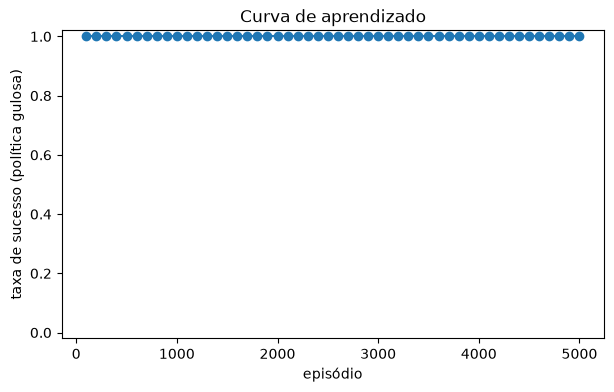

In [44]:
before_training = record_episode(random_policy, "before_training")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(hist["eval_episode"], hist["eval_success"], marker="o")
ax.set_xlabel("episódio"); ax.set_ylabel("taxa de sucesso (política gulosa)")
ax.set_ylim(-0.02, 1.02); ax.set_title("Curva de aprendizado")
plt.show()

### Metrics

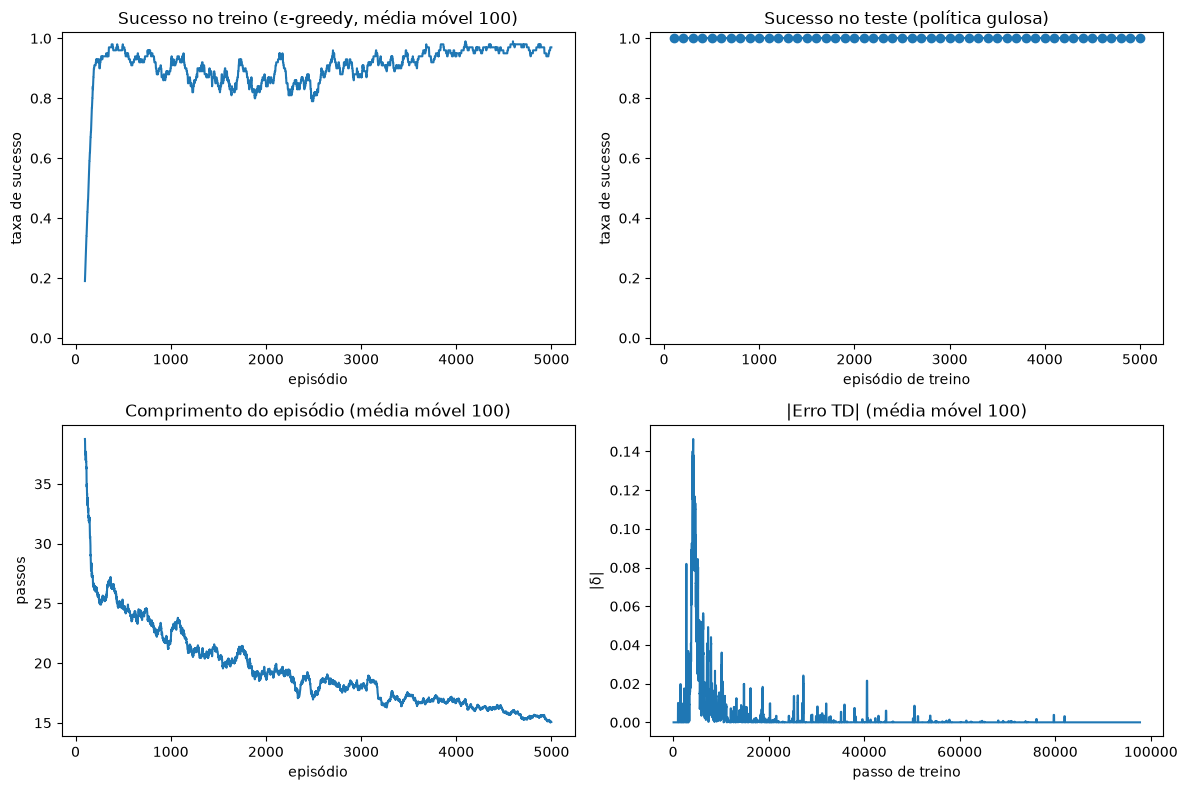

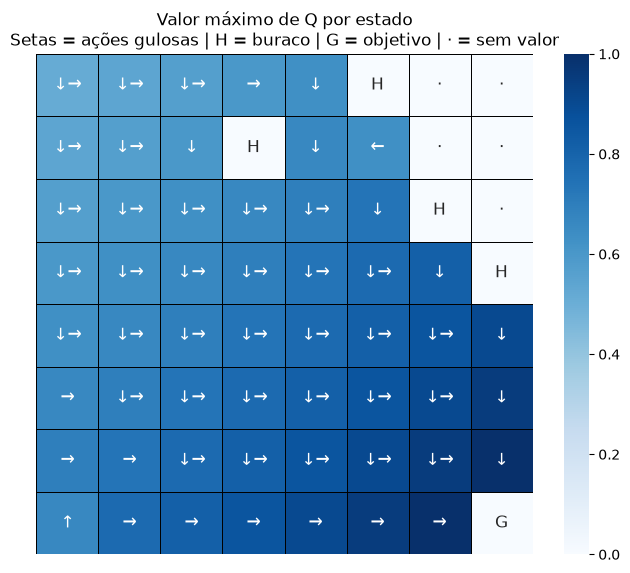

In [45]:
ARROWS = {0: "←", 1: "↓", 2: "→", 3: "↑"}


def moving_average(x, window):
    """Média móvel sem artefato de borda. Retorna (x_pos, média) alinhados ao fim da janela."""
    x = np.asarray(x, dtype=float)
    if len(x) < window:
        return np.array([]), np.array([])
    ma = np.convolve(x, np.ones(window) / window, mode="valid")
    return np.arange(window - 1, len(x)), ma


def plot_training_curves(hist, agent, window=100):
    fig, axs = plt.subplots(2, 2, figsize=(12, 8))

    xs, ma = moving_average(hist["reward"], window)
    axs[0, 0].plot(xs, ma)
    axs[0, 0].set(title=f"Sucesso no treino (ε-greedy, média móvel {window})",
                  xlabel="episódio", ylabel="taxa de sucesso", ylim=(-0.02, 1.02))

    axs[0, 1].plot(hist["eval_episode"], hist["eval_success"], marker="o")
    axs[0, 1].set(title="Sucesso no teste (política gulosa)",
                  xlabel="episódio de treino", ylabel="taxa de sucesso", ylim=(-0.02, 1.02))

    xs, ma = moving_average(hist["steps"], window)
    axs[1, 0].plot(xs, ma)
    axs[1, 0].set(title=f"Comprimento do episódio (média móvel {window})",
                  xlabel="episódio", ylabel="passos")

    xs, ma = moving_average(np.abs(agent.training_error), window)
    axs[1, 1].plot(xs, ma)
    axs[1, 1].set(title=f"|Erro TD| (média móvel {window})", xlabel="passo de treino", ylabel="|δ|")

    plt.tight_layout()
    plt.show()


def plot_policy_map(agent, desc):
    """Heatmap de max Q com setas gulosas; empates mostram várias setas; H, G e '·' (sem valor) explícitos."""
    q = agent.q_table
    n_rows, n_cols = len(desc), len(desc[0])
    labels = np.empty((n_rows, n_cols), dtype=object)

    for s in range(q.shape[0]):
        r, c = divmod(s, n_cols)
        if desc[r][c] in "HG":
            labels[r, c] = desc[r][c]
        elif q[s].max() > 0:
            best = np.flatnonzero(np.isclose(q[s], q[s].max()))
            labels[r, c] = "".join(ARROWS[a] for a in best)
        else:
            labels[r, c] = "·"  # estado sem valor aprendido

    fig, ax = plt.subplots(figsize=(8, 6.5))
    sns.heatmap(q.max(axis=1).reshape(n_rows, n_cols), annot=labels, fmt="", cmap="Blues",
                linewidths=0.7, linecolor="black", xticklabels=False, yticklabels=False,
                annot_kws={"fontsize": "large"}, ax=ax)
    ax.set_title("Valor máximo de Q por estado\nSetas = ações gulosas | H = buraco | G = objetivo | · = sem valor")
    plt.show()


plot_training_curves(hist, agent)
plot_policy_map(agent, desc)

Using Q-learning method
Using Q-learning method
Using Q-learning method
Using Q-learning method
Using Q-learning method
Using Sarsa method
Using Sarsa method
Using Sarsa method
Using Sarsa method
Using Sarsa method
Using Q-learning method
Using Q-learning method
Using Q-learning method
Using Q-learning method
Using Q-learning method
Using Sarsa method
Using Sarsa method
Using Sarsa method
Using Sarsa method
Using Sarsa method
Q-learning slippery=False -> 1.00 ± 0.00
SARSA      slippery=False -> 1.00 ± 0.00
Q-learning slippery=True  -> 0.74 ± 0.08
SARSA      slippery=True  -> 0.75 ± 0.04


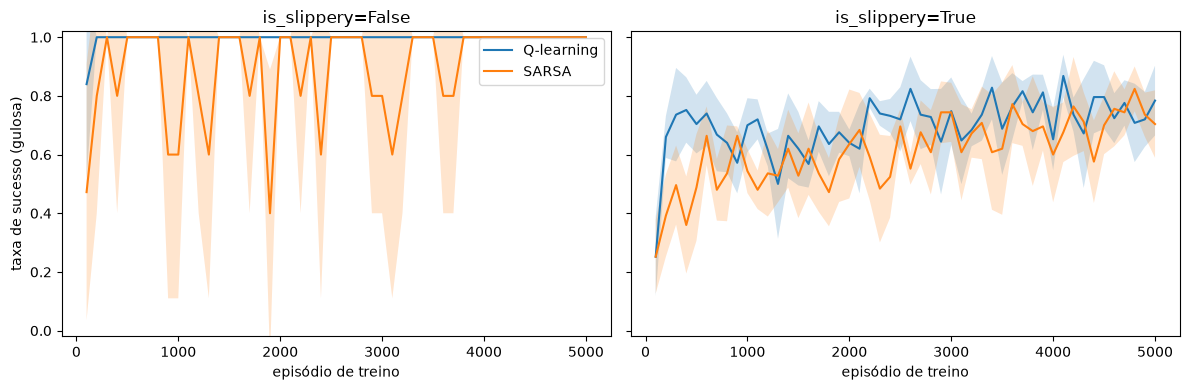

In [46]:
resultados = {}
for slippery in (False, True):
    IS_SLIPPERY = slippery          # lido por make_env()
    for nome, sarsa in (("Q-learning", False), ("SARSA", True)):
        resultados[(nome, slippery)] = [
            train(sarsa, seed=k, verbose=False)[1] for k in range(5)
        ]

def valor_final(h, k=5):
    return np.mean(h["eval_success"][-k:])

for (nome, slippery), hs in resultados.items():
    v = [valor_final(h) for h in hs]
    print(f"{nome:10s} slippery={slippery!s:5s} -> {np.mean(v):.2f} ± {np.std(v, ddof=1):.2f}")

# Figura 1: média e faixa entre sementes
fig, axs = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, slippery in zip(axs, (False, True)):
    for nome in ("Q-learning", "SARSA"):
        hs = resultados[(nome, slippery)]
        x = hs[0]["eval_episode"]
        Y = np.array([h["eval_success"] for h in hs])
        ax.plot(x, Y.mean(0), label=nome)
        ax.fill_between(x, Y.mean(0) - Y.std(0), Y.mean(0) + Y.std(0), alpha=0.2)
    ax.set(title=f"is_slippery={slippery}", xlabel="episódio de treino", ylim=(-0.02, 1.02))
axs[0].set_ylabel("taxa de sucesso (gulosa)")
axs[0].legend()
plt.tight_layout(); plt.show()

In [47]:
SEEDS = range(5)
resultados = {}  # (algoritmo, slippery) -> lista de (agent, hist)

for slippery in (False, True):
    IS_SLIPPERY = slippery  # lido por make_env()
    for nome, sarsa in (("Q-learning", False), ("SARSA", True)):
        resultados[(nome, slippery)] = [train(sarsa, seed=k, verbose=False) for k in SEEDS]

Using Q-learning method
Using Q-learning method
Using Q-learning method
Using Q-learning method
Using Q-learning method
Using Sarsa method
Using Sarsa method
Using Sarsa method
Using Sarsa method
Using Sarsa method
Using Q-learning method
Using Q-learning method
Using Q-learning method
Using Q-learning method
Using Q-learning method
Using Sarsa method
Using Sarsa method
Using Sarsa method
Using Sarsa method
Using Sarsa method


In [48]:
from collections import deque

def passos_minimos(desc):
    """BFS no mapa: menor número de passos de S até G, sem passar por buracos."""
    n, m = len(desc), len(desc[0])
    fila, vis = deque([(0, 0, 0)]), {(0, 0)}
    while fila:
        r, c, d = fila.popleft()
        if desc[r][c] == "G":
            return d
        for dr, dc in ((0, 1), (1, 0), (0, -1), (-1, 0)):
            nr, nc = r + dr, c + dc
            if 0 <= nr < n and 0 <= nc < m and (nr, nc) not in vis and desc[nr][nc] != "H":
                vis.add((nr, nc)); fila.append((nr, nc, d + 1))

def ep_convergencia(h, limiar=0.95):
    """Primeiro episódio de avaliação a partir do qual o sucesso fica >= limiar até o fim."""
    ok = np.array(h["eval_success"]) >= limiar
    eps = np.array(h["eval_episode"])
    if not ok[-1]:
        return np.nan                      # não convergiu
    if ok.all():
        return eps[0]
    return eps[len(ok) - np.argmin(ok[::-1])]  # início da sequência final de True

def ms(v, casas=2):
    v = np.asarray(v, dtype=float)
    n = int(np.sum(~np.isnan(v)))
    if n == 0:
        return "não convergiu"
    sd = np.nanstd(v, ddof=1) if n > 1 else float("nan")
    return f"{np.nanmean(v):.{casas}f} ± {sd:.{casas}f}"

K = 5  # valor final = média dos últimos 5 pontos de avaliação
nomes = {(False, "Q-learning"): "A", (False, "SARSA"): "B",
         (True, "Q-learning"): "C", (True, "SARSA"): "D"}

print("| Cenário | Sucesso final | Passos médios | Episódios até convergir | max Q(S) |")
print("|---|---|---|---|---|")
for (nome, slip), pares in resultados.items():
    succ = [np.mean(h["eval_success"][-K:]) for _, h in pares]
    leng = [np.mean(h["eval_len"][-K:]) for _, h in pares]
    conv = [ep_convergencia(h) for _, h in pares]
    qS   = [a.q_table[0].max() for a, _ in pares]
    n_ok = int(np.sum(~np.isnan(conv)))
    print(f"| {nomes[(slip, nome)]}: {nome}, {'escorregadio' if slip else 'determinístico'} "
          f"| {ms(succ)} | {ms(leng, 1)} | {ms(conv, 0)} ({n_ok}/5) | {ms(qS, 3)} |")

d = passos_minimos(desc)
print(f"\nReferência (determinístico): passos mínimos = {d} | γ^(d−1) = {0.95**(d-1):.3f}")

| Cenário | Sucesso final | Passos médios | Episódios até convergir | max Q(S) |
|---|---|---|---|---|
| A: Q-learning, determinístico | 1.00 ± 0.00 | 14.0 ± 0.0 | 120 ± 45 (5/5) | 0.513 ± 0.000 |
| B: SARSA, determinístico | 1.00 ± 0.00 | 14.0 ± 0.0 | 3400 ± 339 (5/5) | 0.481 ± 0.010 |
| C: Q-learning, escorregadio | 0.74 ± 0.08 | 59.5 ± 2.4 | 5000 ± nan (1/5) | 0.131 ± 0.014 |
| D: SARSA, escorregadio | 0.79 ± 0.06 | 59.3 ± 5.3 | não convergiu (0/5) | 0.068 ± 0.010 |

Referência (determinístico): passos mínimos = 14 | γ^(d−1) = 0.513
